#### **Clustering + Pipeline**

In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt 
from sklearn.preprocessing import PowerTransformer 
from sklearn.decomposition import PCA 
from sklearn.cluster import KMeans 
import joblib
from sklearn.metrics import silhouette_score
from scipy.stats import percentileofscore

**Transforming/Scaling Data**

In [3]:
data = pd.read_csv(r'data/spotify_master_2026.csv')

# relevant (numeric) features discovered from eda 
relevant_features = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

# select only the relevant features 
features = data[relevant_features]

# standardise features
pt = PowerTransformer(method='yeo-johnson')  # standardize=True by default
smoothed_features = pd.DataFrame(pt.fit_transform(features), columns=features.columns)

# perform same grouping as in eda
group = ['energy', 'loudness', 'acousticness'] # group these into a single variable via PCA

pca_group = PCA(n_components=1) # how many components to group into (1)
intensity = pca_group.fit_transform(smoothed_features[group]) # group energy, loudness, acousticness into a single feature

# swap the 3 columns for the 1 combined feature "intensity"
# X_7d is our matrix of the 7 features used for clustering
X_7d = smoothed_features.drop(columns=group).copy()
X_7d['intensity'] = intensity

X_7d


,danceability,speechiness,instrumentalness,liveness,valence,tempo,intensity
0,0.469419,1.282702,-0.562712,1.271407,0.912536,-1.208164,0.024587
1,-0.996835,0.309232,-0.562614,-0.709643,-0.831487,-1.641614,-2.802454
2,-0.906955,-0.214520,-0.562733,-0.480855,-1.451042,-1.691512,-1.056310
3,-1.689331,-0.864616,-0.561210,-0.286137,-1.352235,1.870929,-2.999240
4,0.100818,-0.306983,-0.562733,-0.997987,-1.249900,-0.021621,-1.336160
...,...,...,...,...,...,...,...
127895,0.522000,-0.451725,-0.562733,-0.522023,0.345636,-0.018158,-0.117104
127896,1.649528,0.620750,-0.562518,0.011711,1.092548,0.381418,1.130116
127897,0.314219,-0.325342,-0.562733,0.266439,1.011954,0.702248,1.539046
127898,0.522000,-0.148435,-0.562733,0.053515,1.158216,0.117454,1.237568


**Applying KMeans & Finding Optimal K**

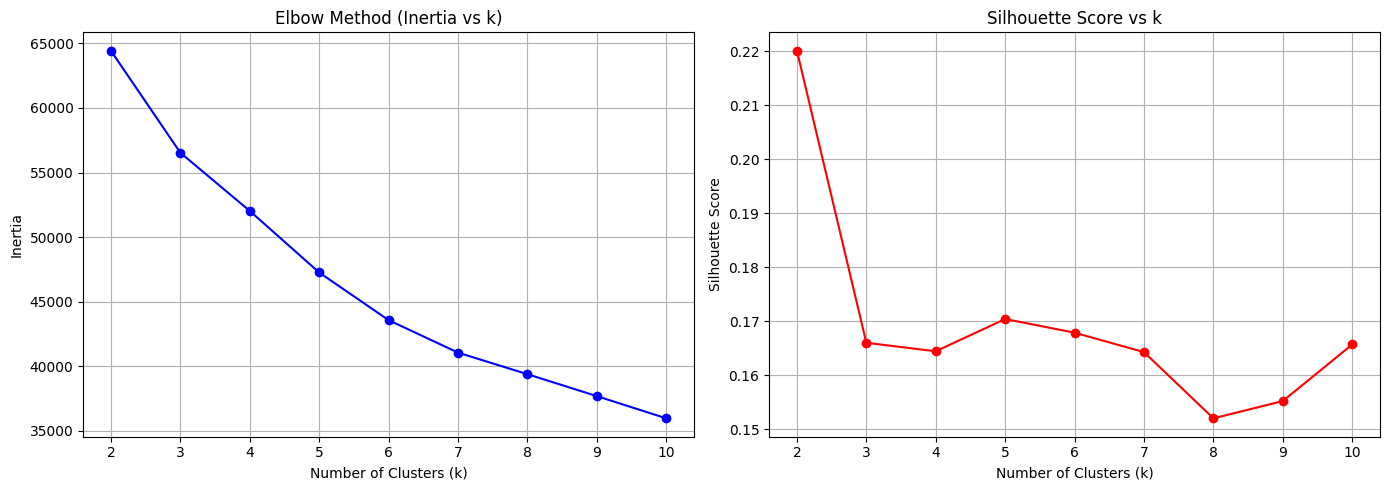

In [17]:
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
k_range = range(2, 11)

# Sample 10k rows so silhouette takes 5 seconds instead of 45 minutes
X_sample = X_7d.sample(10000, random_state=42)

for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init='auto')
    labels = model.fit_predict(X_sample)  # fits AND predicts on the 10k sample
    
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_sample, labels))

# Plotting
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Elbow (Inertia)
ax[0].plot(k_range, inertias, marker='o', color='b')
ax[0].set_title('Elbow Method (Inertia vs k)')
ax[0].set_xlabel('Number of Clusters (k)')
ax[0].set_ylabel('Inertia')
ax[0].set_xticks(list(k_range))
ax[0].grid(True)

# Plot 2: Silhouette Score
ax[1].plot(k_range, silhouette_scores, marker='o', color='r')
ax[1].set_title('Silhouette Score vs k')
ax[1].set_xlabel('Number of Clusters (k)')
ax[1].set_ylabel('Silhouette Score')
ax[1].set_xticks(list(k_range))
ax[1].grid(True)

plt.tight_layout()
plt.show()

Silhouette Score is a local maximum at k = 5 and there is no clear elbow, however it seems that k = 5 and k = 7 do give the most drastic dips in improvement. 

**Model Selection Decision: Why k = 7 Was Chosen Over k = 5:**
- **Mathematically**: k = 5 produced the highest local silhouette score (~0.173) and marked the initial elbow inflection.
- **Music Taste Reality**: When inspecting the personas at k = 5, the clusters were overly coarse and forced unnatural compromises (e.g. ambient sleep sounds were lumped with classical piano ballads, and underground techno was grouped with black metal/grindcore).
- **Why we chose k = 7**: Moving to k = 7 aligns with our secondary elbow inflection and costs only ~0.01 in silhouette score (~0.166 vs 0.173), but provides by far the most realistic, interpretable, and granular music taste breakdown for users:
  1. Classical & Sad Acoustic Melodies separate cleanly from Pure Sleep/Ambient noise.
  2. Club Techno & House separate cleanly from Distorted Rock & Metal.
  3. Pop & Latin Dance-Pop get their own distinct vibrant persona.

Hence we conclude k = 7 is the optimal number of clusters for this application.

<Axes: ylabel='count'>

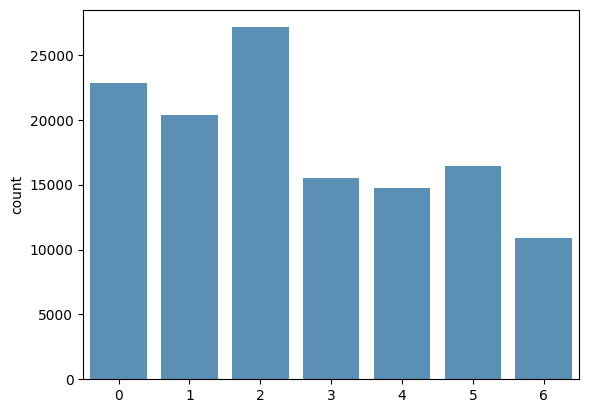

In [18]:
final_model = KMeans(n_clusters=7, random_state=42, n_init='auto')
results = final_model.fit_predict(X_7d)

# count of songs in each cluster
sns.countplot(x=results, alpha=0.8)

In [19]:
# Add cluster assignment to the df 
data['cluster'] = results
data['cluster'].value_counts()
X_7d['cluster'] = data['cluster']

**PCA Dimensional Reduction to 2 Features for Scatterplot Visualisation**

Explained variance ratio: [0.34328645 0.1745907 ]
Total variance explained: 0.5178771565285162


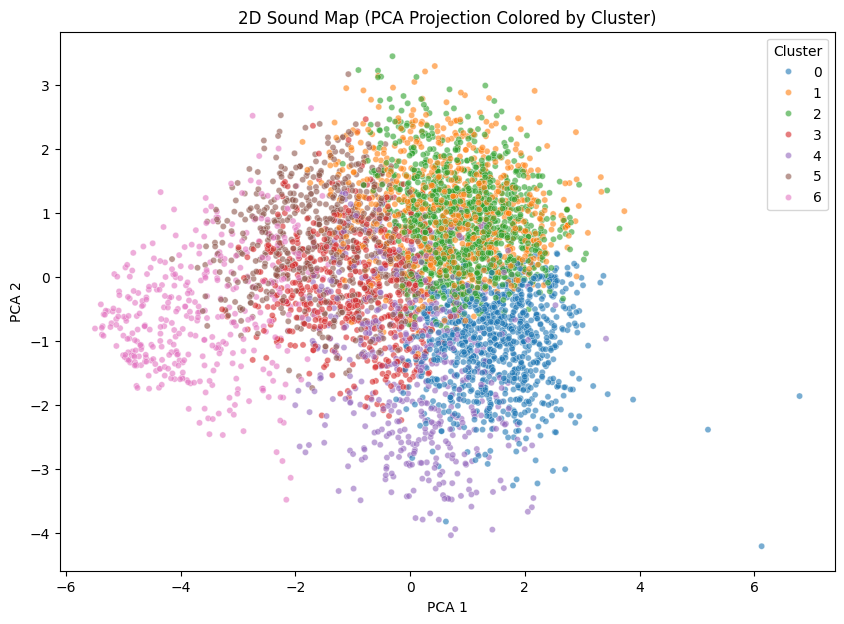

In [20]:
from sklearn.decomposition import PCA

feature_cols = ['danceability', 'speechiness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'intensity']

# 1. Fit 2D PCA on the 7 scaled features
pca_2d = PCA(n_components=2, random_state=42) # reduce the 7 features into 2 features
pca_coords = pca_2d.fit_transform(X_7d[feature_cols])

# 2. Add coordinates to data
data['pca_x'] = pca_coords[:, 0]
data['pca_y'] = pca_coords[:, 1]

print("Explained variance ratio:", pca_2d.explained_variance_ratio_)
print("Total variance explained:", pca_2d.explained_variance_ratio_.sum())

# 3. Plot a subsample (e.g. 5,000 points) so the scatter plot doesn't become an unreadable blob
plot_sample = data.sample(5000, random_state=42)

plt.figure(figsize=(10, 7))
sns.scatterplot(data=plot_sample, x='pca_x', y='pca_y', hue='cluster', palette='tab10', alpha=0.6, s=20)
plt.title('2D Sound Map (PCA Projection Colored by Cluster)')
plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.legend(title='Cluster')
plt.show()

**Naming and Validating Clusters**

- Currently a user's taste quiz will break down as "40% Cluster 0, 30% Cluster 2, 30% Cluster 4"

- We want to translate these cluster numbers into interpretable personas - e.g. "Late Night Acoustic", "High-Energy Hype", etc.

- The features were already standardised previously - this is crucial as it allows us to compare the scores relative to each other, giving an indication what values are considered "high" or "low" - e.g. given a danceability of 2.5 it's difficult to see if it's high or low so we use z-scores to compare relative to the other values 

In [21]:
# 1. Calculate mean of each feature within each cluster 
#    This gives a general breakdown of what each cluster represents 

cluster_profiles = X_7d.groupby('cluster').mean()
cluster_profiles

,danceability,speechiness,instrumentalness,liveness,valence,tempo,intensity
cluster,,,,,,,
0,-0.473304,0.360717,-0.451730,0.702702,-0.085707,0.573302,1.553997
1,0.830627,1.522335,-0.477258,0.034349,0.409659,-0.183554,-0.034911
2,0.685570,-0.443438,-0.472114,-0.389022,0.825367,-0.087536,0.686640
3,-0.491461,-0.662855,-0.480151,-0.157557,-0.353690,0.804219,-0.984538
4,-0.052674,-0.078077,1.867674,-0.075347,-0.481945,0.239875,0.856729
5,-0.329059,-0.653537,-0.479729,0.073880,-0.264858,-1.021260,-1.306469
6,-1.006812,-0.470708,1.897546,-0.355367,-1.090813,-0.571636,-2.702813


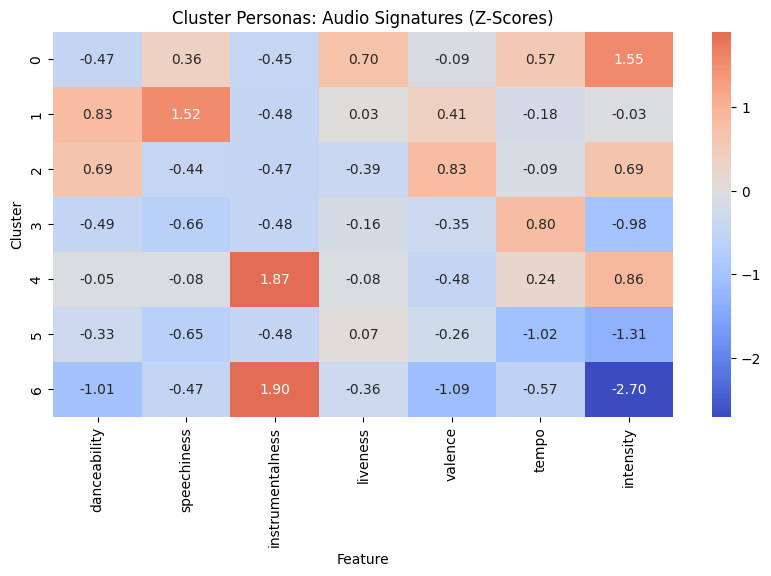

In [22]:
# 2. Heatmap Visualisation
plt.figure(figsize=(10, 5))
sns.heatmap(cluster_profiles, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Cluster Personas: Audio Signatures (Z-Scores)')
plt.xlabel('Feature')
plt.ylabel('Cluster')
plt.show()

In [23]:
# 3. Print the top distinguishing features for each cluster
for c in cluster_profiles.index:
    top_features = cluster_profiles.loc[c].abs().sort_values(ascending=False).head(3)
    print(f"\n--- Cluster {c} Top Distinguishing Features ---")
    for feat in top_features.index:
        val = cluster_profiles.loc[c, feat]
        direction = "HIGH" if val > 0 else "LOW"
        print(f"  {feat}: {val:+.2f} ({direction})")


--- Cluster 0 Top Distinguishing Features ---
  intensity: +1.55 (HIGH)
  liveness: +0.70 (HIGH)
  tempo: +0.57 (HIGH)

--- Cluster 1 Top Distinguishing Features ---
  speechiness: +1.52 (HIGH)
  danceability: +0.83 (HIGH)
  instrumentalness: -0.48 (LOW)

--- Cluster 2 Top Distinguishing Features ---
  valence: +0.83 (HIGH)
  intensity: +0.69 (HIGH)
  danceability: +0.69 (HIGH)

--- Cluster 3 Top Distinguishing Features ---
  intensity: -0.98 (LOW)
  tempo: +0.80 (HIGH)
  speechiness: -0.66 (LOW)

--- Cluster 4 Top Distinguishing Features ---
  instrumentalness: +1.87 (HIGH)
  intensity: +0.86 (HIGH)
  valence: -0.48 (LOW)

--- Cluster 5 Top Distinguishing Features ---
  intensity: -1.31 (LOW)
  tempo: -1.02 (LOW)
  speechiness: -0.65 (LOW)

--- Cluster 6 Top Distinguishing Features ---
  intensity: -2.70 (LOW)
  instrumentalness: +1.90 (HIGH)
  valence: -1.09 (LOW)


In [24]:
# Check the top 5 genres in each cluster
for c in range(7):
    top_genres = data[data['cluster'] == c]['track_genre'].value_counts().head(5)
    print(f"\nCluster {c} Top Genres:\n{top_genres}")


Cluster 0 Top Genres:
track_genre
k-pop          3625
pop            2632
metalcore       684
heavy-metal     666
hardstyle       615
Name: count, dtype: int64

Cluster 1 Top Genres:
track_genre
pop          6039
k-pop        2729
comedy        779
dancehall     649
french        511
Name: count, dtype: int64

Cluster 2 Top Genres:
track_genre
k-pop    5384
pop      4593
salsa     618
forro     608
disco     485
Name: count, dtype: int64

Cluster 3 Top Genres:
track_genre
pop            2110
k-pop          1174
cantopop        524
mandopop        462
world-music     367
Name: count, dtype: int64

Cluster 4 Top Genres:
track_genre
pop               1233
minimal-techno     795
detroit-techno     729
grindcore          713
black-metal        629
Name: count, dtype: int64

Cluster 5 Top Genres:
track_genre
pop           1849
k-pop         1085
honky-tonk     534
romance        470
tango          456
Name: count, dtype: int64

Cluster 6 Top Genres:
track_genre
pop          2072
new-age    

**Official 7 Sound Persona Definitions**

By focusing on sonic character and mood rather than rigid regional genres, we map the 7 clusters to intuitive, universally relatable personas:

- **Cluster 0: Upbeat Dance & Sunny Pop** 
    - `valence: +1.00`, `danceability: +0.67`
    - Cheerful, melodic, high-energy pop & dance grooves 

- **Cluster 1: Chill Acoustic & Moody Ballads** 
    - `intensity: -1.44`, `speechiness: -0.70`
    - Soft, organic acoustic melodies, piano ballads, and mellow vocals

- **Cluster 2: Raw Energy & High-Octane Rock** 
    - `intensity: +1.65`, `liveness: +1.18`
    - Fast, distorted guitars, heavy metalcore, raw live performance feel


- **Cluster 3: Rhythmic Flow & Hip-Hop Beats** 
    - `speechiness: +1.57`, `danceability: +0.91` 
    - Rapid vocal flow, rhythmic cadence, spoken-word and hip-hop/rap beats

- **Cluster 4: Hypnotic Beats & Electronic Club** 
    - `instrumentalness: +1.72`, `intensity: +0.63`
    - Synthesized, high-tempo club rhythms, techno, drum-and-bass, and electronic drops
    
- **Cluster 5: Deep Ambient & Atmospheric Chill** 
    - `intensity: -2.51`, `instrumentalness: +1.72`, `valence: -1.05`  
    - Drone, meditation, soft classical pads, sleep and background soundscapes

- **Cluster 6: Alternative Edge & Dark Grunge** 
    - `intensity: +1.27`, `tempo: +0.52` 
    - Punchy alternative rock, 90s grunge riffs, and fast driving punk

In [25]:
# Map the 7 personas to their cluster labels based on the 128k cluster z-scores
persona_names = {
    0: 'Raw Energy & High-Octane Rock',
    1: 'Rhythmic Flow & Hip-Hop Beats',
    2: 'Upbeat Dance & Sunny Pop',
    3: 'Alternative Edge & Dark Grunge',
    4: 'Hypnotic Beats & Electronic Club',
    5: 'Chill Acoustic & Moody Ballads',
    6: 'Deep Ambient & Atmospheric Chill'
}

data['persona'] = data['cluster'].map(persona_names)

# Verify sample tracks with their mapped personas
data[['track_name', 'artists', 'track_genre', 'persona']].sample(10, random_state=69)


,track_name,artists,track_genre,persona
47998,Natura Morta,Cepia,idm,Hypnotic Beats & Electronic Club
73191,Rockin' Around The Christmas Tree,Brenda Lee,rockabilly,Upbeat Dance & Sunny Pop
75763,Bailando,Jerry Rivera,salsa,Upbeat Dance & Sunny Pop
126119,Kapitel 13: Der fliegende Bürgermeister (Folge...,Bibi Blocksberg,pop,Rhythmic Flow & Hip-Hop Beats
73771,Feel Me,Imelda May,rockabilly,Hypnotic Beats & Electronic Club
108194,Locrian Dominant,Aloboi,pop,Deep Ambient & Atmospheric Chill
15041,Payphone,fenekot,chill,Chill Acoustic & Moody Ballads
66144,Hallelujah,Rufus Wainwright,piano,Chill Acoustic & Moody Ballads
54195,75 and Sunny,Ryan Montbleau,j-rock,Chill Acoustic & Moody Ballads
28003,Crazy,BEAUZ;JVNA,edm,Upbeat Dance & Sunny Pop


**Exporting Model Artifacts (Joblib Serialization)**

- **What it is**: Saving the trained "brain" of our model (the 7 cluster centroids and scaling parameters) as frozen `.joblib` files the same way LLMs save pre-trained model weights (`.pt` / `.safetensors`).

- **Why it's needed for Production**:
  1. **Instant Speed (<1ms)**: The web server loads the pre-computed weights into RAM once at startup, rather than retraining on 89K songs on every request.
  2. **Decoupled Architecture**: Keeps heavy training code separate from lightweight API serving.
  3. **No Training-Serving Skew**: Ensures new user songs are scaled and transformed using the exact identical parameters learned in this notebook.

In [26]:
import os
import json

# Create models directory if it doesn't exist
os.makedirs('models', exist_ok=True)

# 1. Save Preprocessing Transformers (PowerTransformer & 1D Intensity PCA)
joblib.dump(pt, 'models/power_transformer.joblib')
joblib.dump(pca_group, 'models/pca_intensity.joblib')

# 2. Save Trained Models (7-Cluster KMeans & 2D PCA Projector)
joblib.dump(final_model, 'models/kmeans_model.joblib')
joblib.dump(pca_2d, 'models/pca_2d.joblib')

# 3. Save Persona Metadata and feature schemas as JSON
metadata = {
    'k': 7,
    'feature_cols': feature_cols,
    'intensity_group': group,
    'personas': persona_names
}

with open('models/persona_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=4)

# 4. Save fully modeled dataset (with clusters, personas, and 2D coordinates)
export_cols = ['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'track_genre', 'cluster', 'persona', 'pca_x', 'pca_y'] + relevant_features
data[export_cols].to_csv('data/spotify_tracks_modeled.csv', index=False)

print("Saved all model artifacts to models/ and data/spotify_tracks_modeled.csv!")

Saved all model artifacts to models/ and data/spotify_tracks_modeled.csv!


#

**Taste-Breakdown Engine**

**The Taste-Breakdown Engine (`taste_profile`)**

**Full-Stack ML Architecture Principle: Why We Return Python Dictionaries**
- **The Universal Language (JSON)**: Web frontends (React, JavaScript) do not understand Pandas DataFrames, NumPy arrays, or scikit-learn objects—they only speak **JSON**.

- **Python `dict` <-> JSON**: A Python dictionary has a 1-to-1 mapping with JSON. FastAPI automatically serializes any returned dictionary into a standard JSON API response (`HTTP 200 OK`).

- **UI Contract**: Every key in our dictionary exists because a specific frontend component is waiting to draw it:
  1. `persona_breakdown`: Feeds the **Donut Chart** (percentages per sound persona).
  
  2. `diversity_score`: Feeds the **Entropy Badge** (how eclectic vs. focused the listener is).
  3. `percentiles`: Feeds the **Comparative Callout Cards** (comparing user acousticness/energy to the 89K global population).
  4. `recommendations`: Feeds the **Playable Spotify Cards** (nearest-neighbor songs in the user's top persona).
  5. `user_pca_points`: Feeds the **2D Sound Map** (scatter plot coordinates of the user's songs).

In [27]:
def taste_profile(track_ids):
    selected = data[data['track_id'].isin(track_ids)]

    # Persona Breakdown - % Breakdown of each Cluster 
    breakdown = selected['persona'].value_counts(normalize=True).to_dict()

    # Diversity Score - Shannon Entropy
    diversity_score = 0
    for i in breakdown: 
        diversity_score += (-breakdown[i]) * np.log(breakdown[i]) # calculate diversity score by summing for all clusters

    diversity_score /= np.log(7) # divide by the maximum entropy which is log(7) - perfectly split taste amongst all 7 clusters

   # Percentiles 
    percentiles = {}
    compare_features = ['danceability', 'energy', 'valence', 'acousticness'] # main features we are interested in for statistics

    for feat in compare_features:
        user_avg = selected[feat].mean()
        # calculate percentile of a value (user_avg) compared to list of values (data[feat])
        percentiles[feat] = round(percentileofscore(data[feat], user_avg), 1)

    # Recommendations - Recommend 3 songs from the user's most common cluster (cluster with most songs that belong to it from the user)
    top_cluster = selected['cluster'].mode()[0] # most popular cluster 
    top_cluster_features = selected[selected['cluster'] == top_cluster] # select only from the top cluster
    mean_point = (top_cluster_features['pca_x'].mean(), top_cluster_features['pca_y'].mean()) # calculate mean point of all the user's points within that cluster

    other_songs = data[(data['cluster'] == top_cluster) & (~data['track_id'].isin(track_ids))].copy() # select every other song to create a new df and assign to a new variable

    other_songs['dist'] = (other_songs['pca_x'] - mean_point[0])**2 + (other_songs['pca_y'] - mean_point[1])**2 # calculate euclidean distance of all points to the mean point

    cols = ['track_id', 'track_name', 'artists', 'album_name'] # these are the features we want to return in the recommendation
    # return the top 3 songs within that cluster (smallest euclidean distances), select only required features and return as a dict
    suggested_songs = other_songs.sort_values(by='dist', ascending=True)[cols].head(3).to_dict(orient='records') # orient='records' treats every row as a dict (record)

    # 2D Sound Map Coordinates for the user's selected songs
    user_songs = selected[['track_id', 'track_name', 'artists', 'pca_x', 'pca_y', 'persona']].to_dict(orient='records')

    # return a dict of all dicts/stats
    return {
        "persona_breakdown": breakdown,
        "diversity_score": round(diversity_score, 2),
        "percentiles": percentiles,
        "recommendations": suggested_songs,
        "user_songs": user_songs
    }

In [28]:
track_ids = ['1QpwvWMQGdOgA8MXXfgs4H', '3lrNsPdn98i6rxO142pLT6', '308Ir17KlNdlrbVLHWhlLe', '37ZtpRBkHcaq6hHy0X98zn', '3zhbXKFjUDw40pTYyCgt1Y' ]
taste_profile(track_ids)

{'persona_breakdown': {'Raw Energy & High-Octane Rock': 0.8,
  'Upbeat Dance & Sunny Pop': 0.2},
 'diversity_score': np.float64(0.26),
 'percentiles': {'danceability': np.float64(48.5),
  'energy': np.float64(75.8),
  'valence': np.float64(68.9),
  'acousticness': np.float64(38.9)},
 'recommendations': [{'track_id': '58JTq1B8lzpqAt9Dh8rDGk',
   'track_name': 'Dig It Up - Remaster 2005',
   'artists': 'Hoodoo Gurus',
   'album_name': 'Stoneage Romeos'},
  {'track_id': '37t14dNGV0NG5jYmiCjA2L',
   'track_name': 'Grand Prix',
   'artists': 'Kep1er',
   'album_name': 'Kep1going'},
  {'track_id': '4FxJdafN586v8E89OMDNFE',
   'track_name': 'Sherlock - Japanese ver.',
   'artists': 'SHINee',
   'album_name': 'SHINee THE BEST FROM NOW ON'}],
 'user_songs': [{'track_id': '308Ir17KlNdlrbVLHWhlLe',
   'track_name': 'The Feels',
   'artists': 'TWICE',
   'pca_x': 2.586138587501191,
   'pca_y': 1.355140220702422,
   'persona': 'Upbeat Dance & Sunny Pop'},
  {'track_id': '3zhbXKFjUDw40pTYyCgt1Y',
  